In [20]:
from sklearn.linear_model import Ridge 
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.metrics import r2_score, root_mean_squared_error, mean_squared_error, mean_absolute_error
import pandas as pd 
from pathlib import Path
import numpy as np 
import seaborn as sns 
import matplotlib.pyplot as plt

In [2]:
BASE_DIR = Path.cwd().parent
DATA_DIR = BASE_DIR / "datasets" / "molecules_v2.csv"

In [3]:
data = pd.read_csv(DATA_DIR)
data.head()

,molecule_id,molecular_weight,logP,TPSA,HBD,HBA,rotatable_bonds,aromatic_rings,boiling_point_c
0,MOL_00000,218.543053,1.149084,74.728164,3,0,4.0,1,313.716356
1,MOL_00001,477.821438,1.787485,66.582419,5,7,0.0,1,60.045075
2,MOL_00002,379.397274,4.836379,35.230783,4,5,9.0,4,-38.137203
3,MOL_00003,319.396318,0.720035,121.453334,4,1,9.0,4,341.276184
4,MOL_00004,120.208388,4.957197,95.324832,3,3,2.0,4,375.938048


In [21]:
# train the model 
X = data[['molecular_weight', "logP", "TPSA", "HBD", "HBA", "rotatable_bonds", "aromatic_rings"]]
y = data['boiling_point_c']

preprocessing = Pipeline(steps=[
    ("imputer", SimpleImputer(strategy='median')),
    ("scaler", StandardScaler())
])

model_pipeline = Pipeline(steps=[
    ("preprocessing", preprocessing),
    ("regression", Ridge())
])

X_train, X_test, y_train, y_test = train_test_split(X, y, random_state=42, test_size=0.3)

print(len(X_train))

model_pipeline.fit(X_train, y_train)
y_pred = model_pipeline.predict(X_test)

def data_metrics(y_true, y_pred, model_name):
    mae = mean_absolute_error(y_true, y_pred)
    mse = mean_squared_error(y_true, y_pred)
    rmse = np.sqrt(mse)
    r2 = r2_score(y_true, y_pred)

    return{
        "Model" : model_name,
        "Root Mean Squared Error" : rmse,
        "Mean Square Error" : mse, 
        "Mean Absolute Error" : mae,
        "R Squared" : r2
    }

data_metrics(y_test, y_pred, "Ridge Model")




3500


{'Model': 'Ridge Model',
 'Root Mean Squared Error': np.float64(105.03352128655965),
 'Mean Square Error': 11032.040593854179,
 'Mean Absolute Error': 85.70010152391804,
 'R Squared': 0.5953792451531612}

In [22]:
# check the residual 
dataframe = pd.DataFrame({
    "y_real" : y_test,
    "y_pred" : y_pred,
    "residual" : y_test - y_pred
})
print(dataframe)

          y_real      y_pred    residual
1501  353.370723  338.282420   15.088303
2586  349.586703  169.150739  180.435964
2653  170.006085  276.851955 -106.845870
1055  332.629414  167.353383  165.276031
705    69.065108  135.628675  -66.563567
...          ...         ...         ...
3563  356.298127  243.141020  113.157107
1538  358.431658  305.769270   52.662389
1837  357.461410  349.302573    8.158837
2380   63.850828   66.100096   -2.249268
1912  -50.910418  -27.644295  -23.266123

[1500 rows x 3 columns]


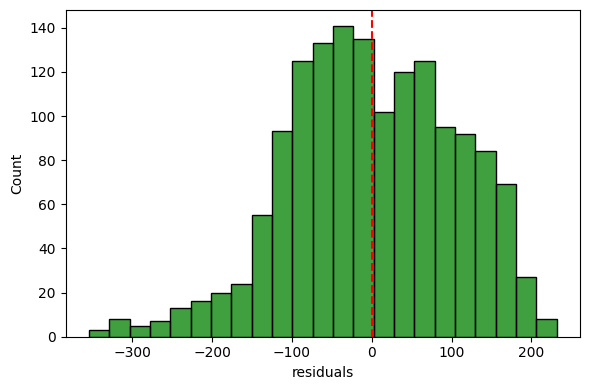

In [23]:
# create a plot of the residuals 
plt.figure(figsize=(6, 4))
sns.histplot(dataframe['residual'], color="green")
plt.axvline(0, linestyle="--", color="red")
plt.xlabel("residuals")
plt.ylabel("Count")
plt.tight_layout()
plt.show()

In [24]:
import joblib
import os

# os.makedirs("../models", exist_ok=False)
joblib.dump(model_pipeline, "../models/model_pipeline.pkl")

['../models/model_pipeline.pkl']